In [1]:
# import package
import numpy as np
import pandas as pd

In [2]:
# baca data dari file CSV
data = pd.read_csv('..\data\jakarta_house_imputed.csv')

In [3]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

d:\anaconda3\Lib\site-packages\seaborn\axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


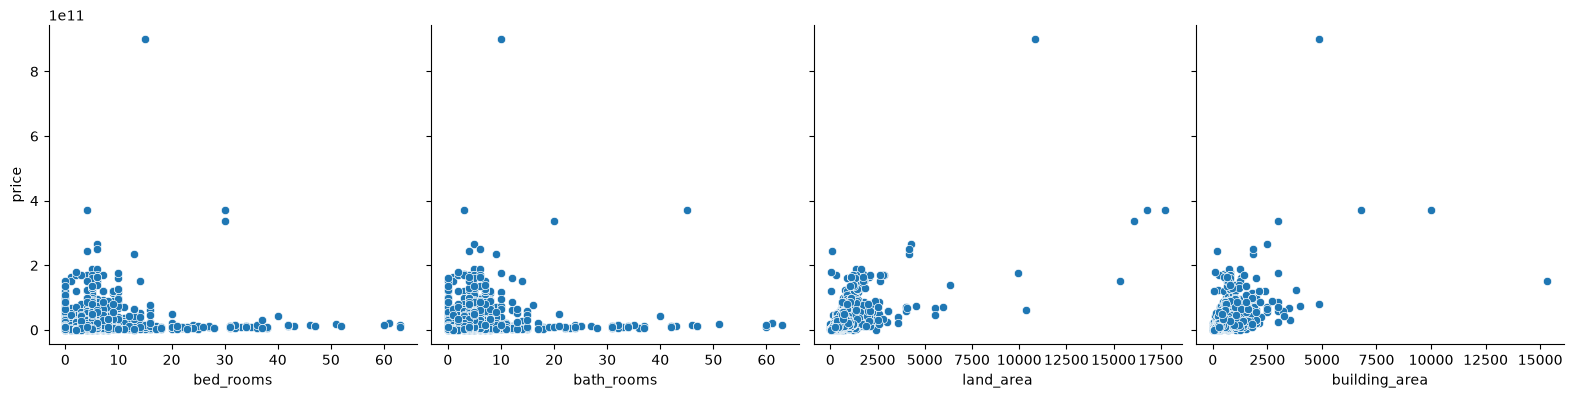

In [6]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['bed_rooms', 'bath_rooms', 'land_area', 'building_area'],
             y_vars='price', size=4, aspect=1, kind='scatter')
plt.show()

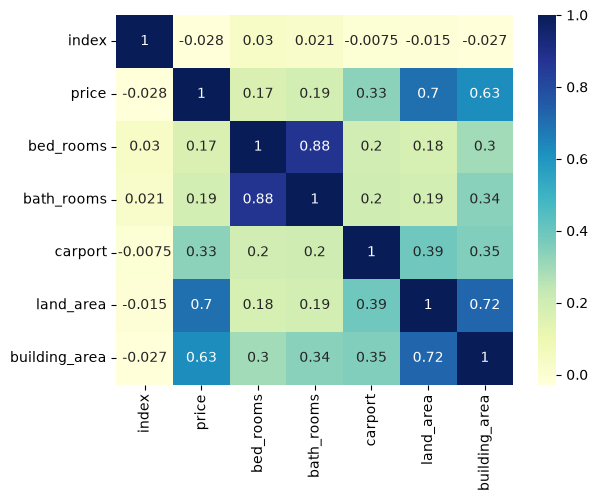

In [7]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [8]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['building_area']
y = data['price']

In [9]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [11]:
import numpy as np
import statsmodels.api as sm

# 1. Bersihin X_train dari NaN dan inf (ubah jadi 0 atau angka aman)
X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)

# 2. Baru tambahkan konstanta dan latih model OLS
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

print("Model OLS berhasil dilatih tanpa error!")
print(lr.summary())

Model OLS berhasil dilatih tanpa error!
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.384
Model:                            OLS   Adj. R-squared:                  0.384
Method:                 Least Squares   F-statistic:                     4363.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:04:33   Log-Likelihood:            -1.7466e+05
No. Observations:                7000   AIC:                         3.493e+05
Df Residuals:                    6998   BIC:                         3.493e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -

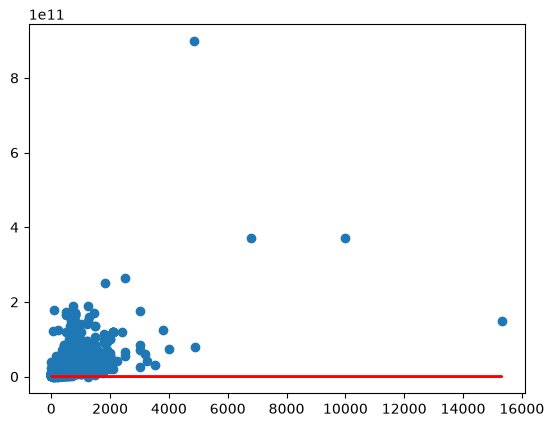

In [12]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

In [13]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

C:\Users\ADVAn\AppData\Local\Temp\ipykernel_19264\594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


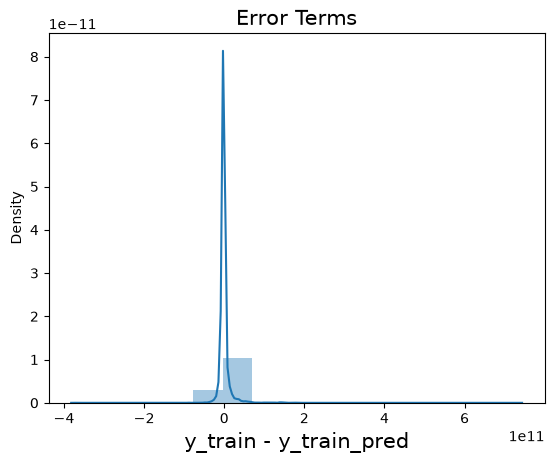

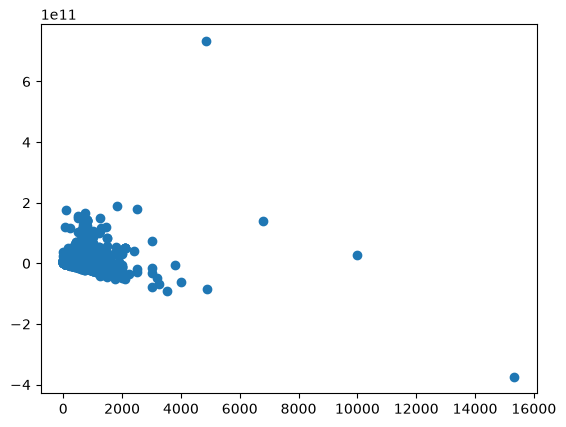

In [14]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [15]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [17]:
import numpy as np
from sklearn.metrics import r2_score

# Pastikan gak ada NaN/inf di y_test dan y_test_pred
mask = ~np.isnan(y_test) & ~np.isnan(y_test_pred)
y_test_clean = y_test[mask]
y_test_pred_clean = y_test_pred[mask]

# Hitung ulang R-squared dengan data yang sudah bersih
r_squared = r2_score(y_test_clean, y_test_pred_clean)
print('R-squared:', r_squared)

R-squared: 0.4156048793510655


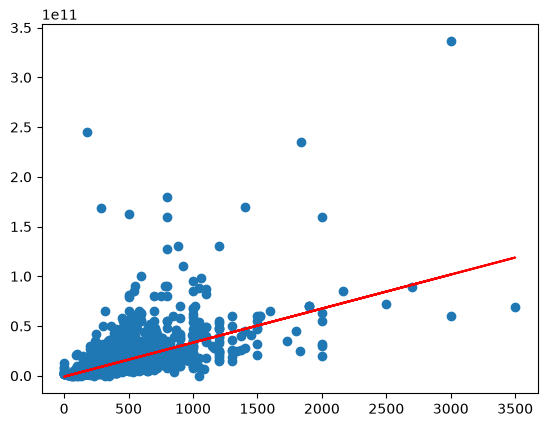

In [18]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()